
🧬 PROCESSING GENERATION 1 / 6
📊 Elite Pareto Front (Rank 1) Size: 2 solutions.

 --- LIVE TOURNAMENT MATCH WINNERS (WITH REPLACEMENT - GEN 1) ---
Parent Slot 00: Index 1 vs Index 16 -> WINNER: Index 1 due to Better Pareto Rank (2 vs 16)
Parent Slot 01: Index 39 vs Index 13 -> WINNER: Index 13 due to Better Pareto Rank (6 vs 7)
Parent Slot 02: Index 17 vs Index 12 -> WINNER: Index 12 due to Better Pareto Rank (4 vs 9)
Parent Slot 03: Index 21 vs Index 14 -> WINNER: Index 14 due to Better Pareto Rank (8 vs 16)
Parent Slot 04: Index 36 vs Index 27 -> WINNER: Index 27 due to Better Pareto Rank (7 vs 15)
Parent Slot 05: Index 17 vs Index 19 -> WINNER: Index 19 due to Better Pareto Rank (1 vs 9)
Parent Slot 06: Index 4 vs Index 11 -> WINNER: Index 4 due to Better Pareto Rank (2 vs 4)
Parent Slot 07: Index 17 vs Index 28 -> WINNER: Index 17 due to Better Pareto Rank (9 vs 13)
Parent Slot 08: Index 27 vs Index 29 -> WINNER: Index 27 due to Better Pareto Rank (7 vs 12)
Parent Slot 09: Index 6 

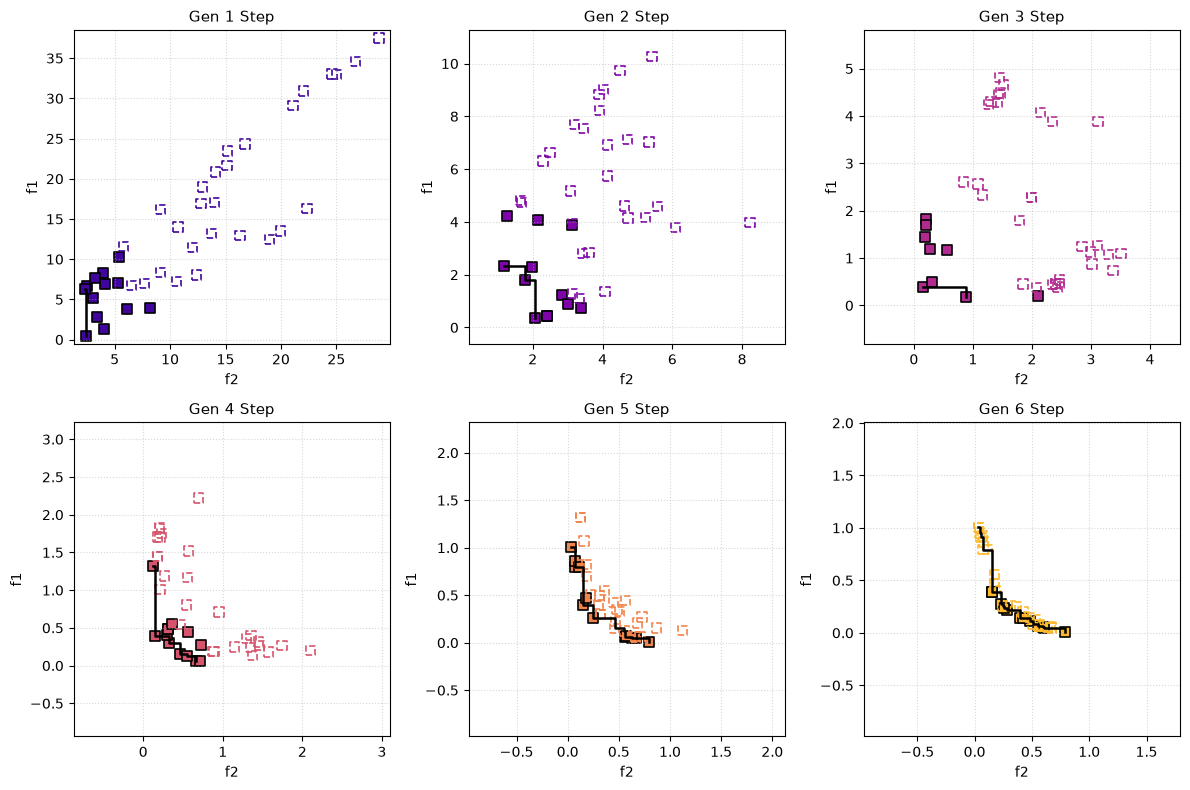

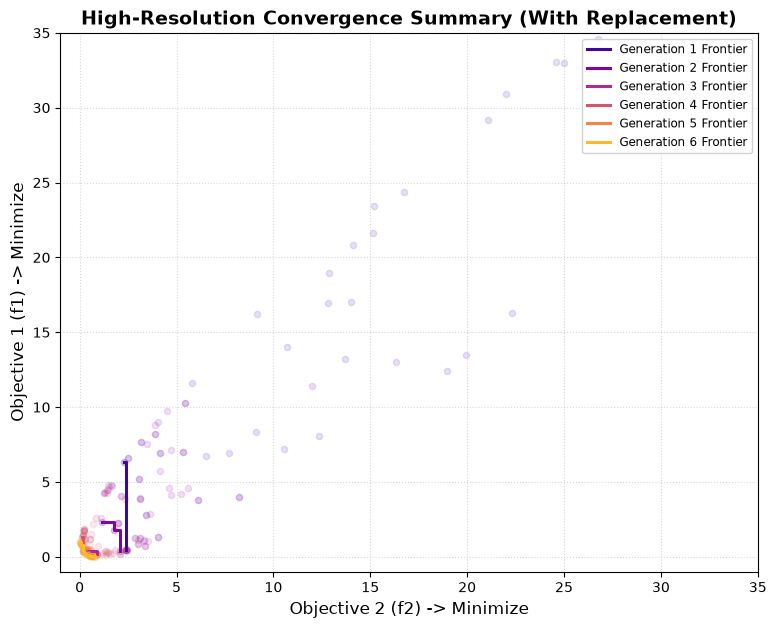

In [46]:
import numpy as np
import matplotlib.pyplot as plt

# ====================================================================================
# STEP 1 & METADATA: CHROMOSOME ENCODING AND ALGORITHM CONFIGURATION
# ====================================================================================
# META-DECISION: Real-valued array encoding is used because our variables represent continuous 
# coordinate parameters. Real-valued arrays avoid the precision loss found in binary string quantization.
POP_SIZE = 40           # Size of active population; large enough for diversity, small enough for notebook speed.
GENERATIONS = 6         # Number of lifetime loops; allows visual tracking of convergence across iterations.
CROSSOVER_PROB = 0.90   # pc: High probability (0.7 ~ 1.0) matches class material to aggressively share elite traits.
MUTATION_PROB = 0.05    # pm: Low probability (0.001 ~ 0.05) prevents the algorithm from devolving into random chaos.
MUTATION_STRENGTH = 0.3 # Dictates how far a coordinate can wander during a rare mutation event.

np.random.seed(42)      # Frozen seed ensures data generation and matrix splits are 100% reproducible.

def evaluate_objectives(chromosomes):
    # META-DECISION: Vectorized matrix evaluation is used here instead of nested Python loops.
    # It evaluates all 40 elements simultaneously using high-speed C-level memory structures.
    # Objective 1 (f1, Y-axis) and Objective 2 (f2, X-axis) are in direct conflict. Minimizing one spikes the other.
    f1 = chromosomes[:, 0]**2 + chromosomes[:, 1]**2
    f2 = (chromosomes[:, 0] - 1)**2 + chromosomes[:, 1]**2
    return np.column_stack((f1, f2))

# ====================================================================================
# STEP 2: MULTI-OBJECTIVE FITNESS SELECTION CRITERION (NSGA-II ENGINE)
# ====================================================================================
def calculate_nsga2_ranks(scores):
    # META-DECISION: Instead of squashing objectives using a weighted sum (F = A - f(x)), which fails 
    # on non-convex spaces, we rank individuals into hierarchical layers (fronts) using Pareto Dominance.
    num_items = len(scores)
    ranks = np.zeros(num_items, dtype=int)
    
    # Math Trick: Use 'np.newaxis' broadcasting to subtract every point from every other point all at once.
    diff = scores[:, np.newaxis, :] - scores[np.newaxis, :, :]
    
    # Pareto Logic Rule Checklist:
    # 1. Is individual i equal or smaller (better) than j in ALL categories? (diff <= 0)
    # 2. Is individual i strictly smaller (better) than j in AT LEAST ONE category? (diff < 0)
    is_equal_or_better = np.all(diff <= 0, axis=2)
    is_strictly_better = np.any(diff < 0, axis=2)
    
    domination_grid = is_equal_or_better & is_strictly_better
    np.fill_diagonal(domination_grid, False) # A point cannot dominate itself
    
    # Sum along columns to count exactly how many times each design gets beaten by someone else
    times_dominated = np.sum(domination_grid, axis=0)
    current_rank = 1
    remaining_pool = np.arange(num_items)
    
    # Peeling Layers: Isolate completely undefeated points (Rank 1), subtract their presence,
    # and find subsequent layers (Rank 2, 3...) until everyone has an assigned front tier.
    while len(remaining_pool) > 0:
        front_mask = (times_dominated[remaining_pool] == 0)
        front_indices = remaining_pool[front_mask]
        if len(front_indices) == 0: break
        ranks[front_indices] = current_rank
        for winner_idx in front_indices:
            times_dominated[domination_grid[winner_idx, :]] -= 1
        remaining_pool = remaining_pool[~front_mask]
        current_rank += 1
    return ranks

def calculate_crowding_distances(scores, ranks):
    # META-DECISION: To prevent "inbreeding" where all points clump up on a single spot of the curve,
    # this tie-breaker metric measures spatial breathing room using geometric neighbor calculations.
    num_items = len(scores)
    crowding_distances = np.zeros(num_items)
    
    for current_rank in np.unique(ranks):
        front_indices = np.where(ranks == current_rank)
        front_size = len(front_indices[0]) # FIXED: Unpacks array safely out of the tuple wrapper
        
        if front_size == 0: continue
        if front_size <= 2:
            crowding_distances[front_indices] = np.inf; continue   
        front_scores = scores[front_indices]
        
        # Perimeter Math: Sort front elements along each axis. Give extreme end-caps infinite priority 
        # so boundaries don't collapse. For interior items, add: (Right Neighbor - Left Neighbor) / Span.
        for obj_idx in range(2):
            sorted_order = np.argsort(front_scores[:, obj_idx])
            sorted_indices = front_indices[0][sorted_order]
            
            crowding_distances[sorted_indices[0]] = np.inf
            crowding_distances[sorted_indices[-1]] = np.inf
            
            span = front_scores[sorted_order[-1], obj_idx] - front_scores[sorted_order[0], obj_idx]
            normalization_factor = span if span != 0 else 1.0
            
            for i in range(1, front_size - 1):
                right_neighbor = scores[sorted_indices[i + 1], obj_idx]
                left_neighbor = scores[sorted_indices[i - 1], obj_idx]
                crowding_distances[sorted_indices[i]] += (right_neighbor - left_neighbor) / normalization_factor
    return crowding_distances

def selection_tournament(chromosomes, ranks, distances):
    chosen = []
    
    # We use global tracking here just to peek at the active generation loop count
    global generation 
    if generation == 0 and len(chosen) == 0:
        print("\n --- LIVE TOURNAMENT MATCH WINNERS (WITH REPLACEMENT - GEN 1) ---")
        
    for slot in range(len(chromosomes)):
        i, j = np.random.choice(len(chromosomes), size=2, replace=False)
        
        # Determine the winner using NSGA-II priority logic
        if ranks[i] < ranks[j]:
            winner = i
            reason = f"Better Pareto Rank ({ranks[i]} vs {ranks[j]})"
        elif ranks[j] < ranks[i]:
            winner = j
            reason = f"Better Pareto Rank ({ranks[j]} vs {ranks[i]})"
        else:
            if distances[i] > distances[j]:
                winner = i
                reason = f"Tied Rank {ranks[i]} | Better Crowding Dist ({distances[i]:.2f} vs {distances[j]:.2f})"
            else:
                winner = j
                reason = f"Tied Rank {ranks[j]} | Better Crowding Dist ({distances[j]:.2f} vs {distances[i]:.2f})"
                
        chosen.append(chromosomes[winner])
        
        # Only print for the first generation to keep your notebook clean
        if generation == 0:
            print(f"Parent Slot {slot:02d}: Index {i} vs Index {j} -> WINNER: Index {winner} due to {reason}")
            
    return np.array(chosen)


def reproduce_and_mutate(parents):
    # META-DECISION: Blend crossover is used because it combines real-valued traits smoothly.
    # Polynomial clipping constraints ensure mutated children don't spawn outside the searchable universe.
    offspring = []
    for i in range(0, len(parents), 2):
        p1, p2 = parents[i], parents[i+1]
        
        # Crossover Operation Check (pc)
        if np.random.rand() < CROSSOVER_PROB:
            alpha = np.random.uniform(0, 1) # Random blending factor slider
            child1 = alpha * p1 + (1 - alpha) * p2
            child2 = alpha * p2 + (1 - alpha) * p1
        else:
            child1, child2 = p1.copy(), p2.copy()
            
        # Mutation Operation Check (pm)
        for child in [child1, child2]:
            if np.random.rand() < MUTATION_PROB:
                child += np.random.uniform(-MUTATION_STRENGTH, MUTATION_STRENGTH, size=2)
            child = np.clip(child, -4.0, 4.0) # Boundary safety wall
            offspring.append(child)
    return np.array(offspring)

# ====================================================================================
# 3. INITIALIZATION & LAYOUT AUTO-GENERATION PIPELINES
# ====================================================================================
# META-DECISION: Population starts completely random to replicate an unbiased search space.
chromosomes = np.random.uniform(-4, 4, size=(POP_SIZE, 2))
history_scores, history_fronts = [], []

# META-DECISION: Subplot grid sizing and progressive timeline colors are calculated 
# 100% dynamically on the fly so you can change GENERATIONS to any value without code breaks.
num_cols = 3 if GENERATIONS <= 6 else 4
num_rows = int(np.ceil(GENERATIONS / num_cols))
cmap = plt.get_cmap('plasma')
generation_colors = [cmap(i) for i in np.linspace(0.1, 0.85, GENERATIONS)]

fig, axes = plt.subplots(num_rows, num_cols, figsize=(num_cols * 4.0, num_rows * 4.0))
axes_flat = np.atleast_1d(axes).flatten()

# ====================================================================================
# 4. RUN GENERATIONAL LOOPS WITH INTERACTIVE LIVE LOGGING
# ====================================================================================

for generation in range(GENERATIONS):
    print(f"\n==================================================")
    print(f"🧬 PROCESSING GENERATION {generation + 1} / {GENERATIONS}")
    print(f"==================================================")
    
    current_scores = evaluate_objectives(chromosomes)
    computed_ranks = calculate_nsga2_ranks(current_scores)
    computed_distances = calculate_crowding_distances(current_scores, computed_ranks)
    
    # Isolate Rank 1 points. Sort left-to-right so the step-front line links coordinates smoothly.
    r1_points = current_scores[computed_ranks == 1]
    sort_order = np.argsort(r1_points[:, 0])
    front_x, front_y = r1_points[sort_order, 0], r1_points[sort_order, 1]
    
    print(f"📊 Elite Pareto Front (Rank 1) Size: {len(r1_points)} solutions.")
    
    history_scores.append(current_scores.copy())
    history_fronts.append((front_x, front_y))
    
    # Execute genetic operations pipeline
    parents = selection_tournament(chromosomes, computed_ranks, computed_distances)
    offspring = reproduce_and_mutate(parents)
    
    # ─── INDENTED LOGIC BLOCK (CONTINUED INSIDE THE GENERATIONAL LOOP) ───
    # META-DECISION: Elitist Environmental Selection Pool Merge (2N)
    # Stacking parents and children into an expanded pool guarantees that the absolute 
    # best designs found are never accidentally overwritten or lost between generations.
    expanded_pool = np.vstack((chromosomes, offspring))
    pool_scores = evaluate_objectives(expanded_pool)
    pool_ranks = calculate_nsga2_ranks(pool_scores)
    pool_distances = calculate_crowding_distances(pool_scores, pool_ranks)
    
    # Math Trick: Use 'np.lexsort' to sort by rank ascending, then distance descending (-).
    final_sort_order = np.lexsort((-pool_distances, pool_ranks))
    surviving_indices = final_sort_order[:POP_SIZE] # Keep the top 40 survivors; slice out the rest.
    
    new_children_count = np.sum(surviving_indices >= POP_SIZE)
    print(f"♻️ Environmental Filter Complete. {POP_SIZE} configurations advanced.")
    print(f"   └─ {POP_SIZE - new_children_count} parents retained | {new_children_count} offspring successfully out-competed ancestors.")
    
    # VISUAL DECISION: Split current generation plot markers. 
    # Solid squares represent selected survivors; hollow frames represent rejected items.
    survived_mask = np.zeros(POP_SIZE, dtype=bool)
    for idx in surviving_indices:
        if idx < POP_SIZE: 
            survived_mask[idx] = True
            
    ax = axes_flat[generation]
    ax.scatter(current_scores[survived_mask, 0], current_scores[survived_mask, 1], 
               color=generation_colors[generation], marker='s', edgecolors='black', lw=1.2, s=45, label='Selected')
    ax.scatter(current_scores[~survived_mask, 0], current_scores[~survived_mask, 1], 
               facecolors='none', marker='s', edgecolors=generation_colors[generation], lw=1.2, linestyle='--', s=45, label='Rejected')
    
    # VISUAL DECISION: 'where=post' maps a clean, horizontal-vertical discrete staircase line
    # that matches the textbook stair-step boundary requested in your assignment diagram.
    ax.step(front_x, front_y, where='post', color='black', lw=1.8, zorder=2)
    ax.set_title(f"Gen {generation + 1} Step", fontsize=11)
    ax.set_xlabel("f2")
    ax.set_ylabel("f1")
    ax.grid(True, linestyle=":", alpha=0.5)
    ax.set_xlim(current_scores[:, 0].min() - 1, current_scores[:, 0].max() + 1)
    ax.set_ylim(current_scores[:, 1].min() - 1, current_scores[:, 1].max() + 1)
    
    chromosomes = expanded_pool[surviving_indices]

# ─── OUTSIDE THE LOOP (BACK TO GENERIC ALIGNMENT LEVEL) ───
# Hide trailing empty subplots if grid shapes leave blank boxes on the frame edge
for blank_ax_idx in range(GENERATIONS, len(axes_flat)):
    axes_flat[blank_ax_idx].set_visible(False)

plt.tight_layout()
plt.show() 

# ====================================================================================
# 5. DECODING THE RESULTS (HIGH-RESOLUTION CONVERGENCE SUMMARY)
# ====================================================================================
final_scores = evaluate_objectives(chromosomes)
final_ranks = calculate_nsga2_ranks(final_scores)
final_distances = calculate_crowding_distances(final_scores, final_ranks)

# VISUAL DECISION: An independent large figure is initialized at the end instead of a small grid subplot box. 
# This grants ample pixel breathing room to cleanly map the complete progressive history timeline of lines shifting.
plt.figure(figsize=(9, 7)) 

for generation in range(GENERATIONS):
    scores_hist = history_scores[generation]
    fx, fy = history_fronts[generation]
    
    plt.scatter(scores_hist[:, 0], scores_hist[:, 1], color=generation_colors[generation], alpha=0.12, s=20)
    plt.step(fx, fy, where='post', color=generation_colors[generation], lw=2.2, 
             label=f'Generation {generation + 1} Frontier')

plt.title("High-Resolution Convergence Summary (With Replacement)", fontsize=14, weight='bold')
plt.xlabel("Objective 2 (f2) -> Minimize", fontsize=12)
plt.ylabel("Objective 1 (f1) -> Minimize", fontsize=12)

# Axis boundaries are fixed to map out a clear macro overview of population migration over time
plt.xlim(-1, 35)
plt.ylim(-1, 35)
plt.grid(True, linestyle=":", alpha=0.5)
plt.legend(loc='upper right', fontsize='small', framealpha=0.9)
plt.show()


🧬 PROCESSING GENERATION 1 / 6
📊 Elite Pareto Front (Rank 1) Size: 2 solutions.

 --- LIVE TOURNAMENT MATCH WINNERS (WITHOUT REPLACEMENT - GEN 1) ---
Round 1 | Parent Slot 00: Index 6 vs Index 9 (Removed from pool) -> WINNER: Index 9 due to Better Pareto Rank (2 vs 7)
Round 1 | Parent Slot 01: Index 8 vs Index 14 (Removed from pool) -> WINNER: Index 8 due to Better Pareto Rank (2 vs 8)
Round 1 | Parent Slot 02: Index 37 vs Index 36 (Removed from pool) -> WINNER: Index 37 due to Better Pareto Rank (3 vs 15)
Round 1 | Parent Slot 03: Index 26 vs Index 28 (Removed from pool) -> WINNER: Index 26 due to Better Pareto Rank (10 vs 13)
Round 1 | Parent Slot 04: Index 4 vs Index 2 (Removed from pool) -> WINNER: Index 4 due to Better Pareto Rank (2 vs 11)
Round 1 | Parent Slot 05: Index 17 vs Index 12 (Removed from pool) -> WINNER: Index 12 due to Better Pareto Rank (4 vs 9)
Round 1 | Parent Slot 06: Index 31 vs Index 39 (Removed from pool) -> WINNER: Index 31 due to Better Pareto Rank (4 vs 7)


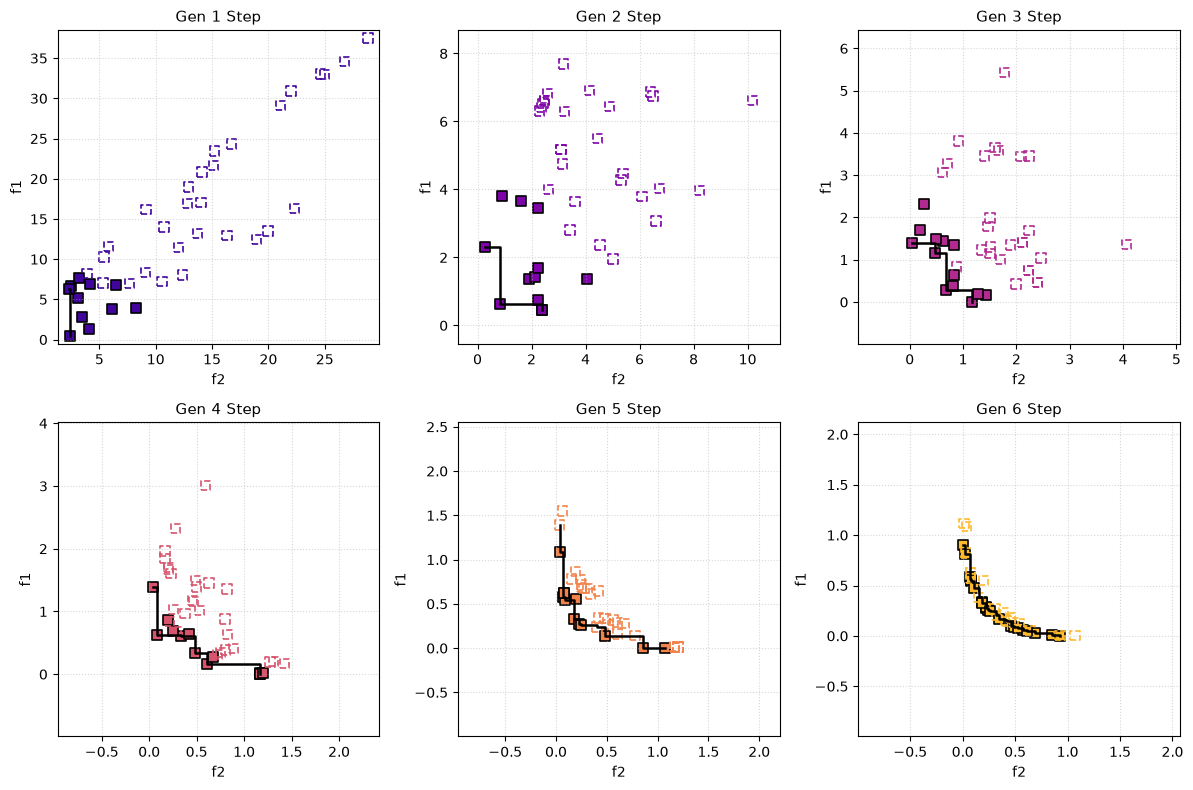

<Figure size 900x700 with 0 Axes>

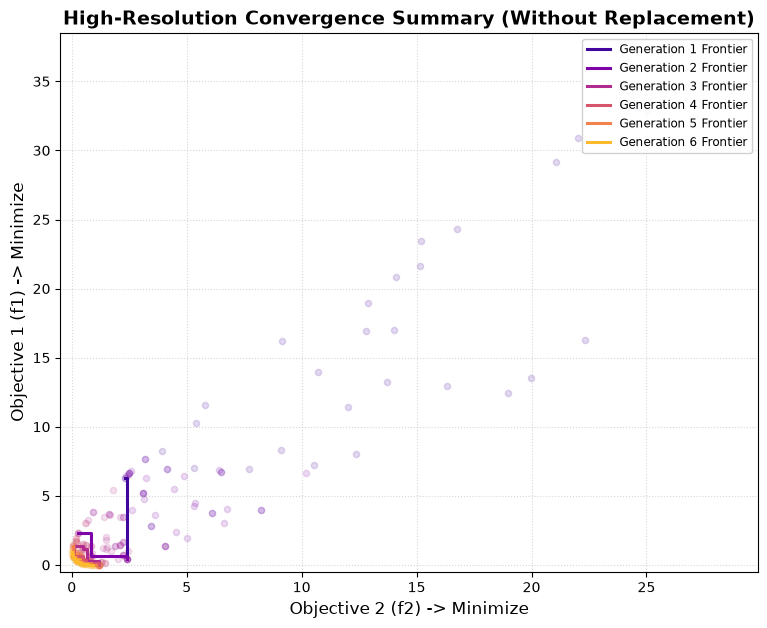

In [47]:
import numpy as np
import matplotlib.pyplot as plt

# =====================================================================
# STEP 1 & PARAMETERS: ENCODING AND CONFIGURATION
# =====================================================================
POP_SIZE = 40           
GENERATIONS = 6         # Fully dynamic, set to any value
CROSSOVER_PROB = 0.90   
MUTATION_PROB = 0.05    
MUTATION_STRENGTH = 0.3 

np.random.seed(42)

def evaluate_objectives(chromosomes):
    f1 = chromosomes[:, 0]**2 + chromosomes[:, 1]**2
    f2 = (chromosomes[:, 0] - 1)**2 + chromosomes[:, 1]**2
    return np.column_stack((f1, f2))

# =====================================================================
# STEP 2: MULTI-OBJECTIVE FITNESS SELECTION CRITERION (NSGA-II MECHANICS)
# =====================================================================
def calculate_nsga2_ranks(scores):
    num_items = len(scores)
    ranks = np.zeros(num_items, dtype=int)
    diff = scores[:, np.newaxis, :] - scores[np.newaxis, :, :]
    is_equal_or_better = np.all(diff <= 0, axis=2)
    is_strictly_better = np.any(diff < 0, axis=2)
    domination_grid = is_equal_or_better & is_strictly_better
    np.fill_diagonal(domination_grid, False)
    times_dominated = np.sum(domination_grid, axis=0)
    current_rank = 1
    remaining_pool = np.arange(num_items)
    while len(remaining_pool) > 0:
        front_mask = (times_dominated[remaining_pool] == 0)
        front_indices = remaining_pool[front_mask]
        if len(front_indices) == 0: break
        ranks[front_indices] = current_rank
        for winner_idx in front_indices:
            times_dominated[domination_grid[winner_idx, :]] -= 1
        remaining_pool = remaining_pool[~front_mask]
        current_rank += 1
    return ranks

def calculate_crowding_distances(scores, ranks):
    num_items = len(scores)
    crowding_distances = np.zeros(num_items)
    for current_rank in np.unique(ranks):
        front_indices = np.where(ranks == current_rank)
        front_size = len(front_indices)
        if front_size == 0: continue
        if front_size <= 2:
            crowding_distances[front_indices] = np.inf; continue   
        front_scores = scores[front_indices]
        for obj_idx in range(2):
            sorted_order = np.argsort(front_scores[:, obj_idx])
            sorted_indices = front_indices[sorted_order]
            crowding_distances[sorted_indices] = np.inf
            crowding_distances[sorted_indices[-1]] = np.inf
            span = front_scores[sorted_order[-1], obj_idx] - front_scores[sorted_order, obj_idx]
            normalization_factor = span if span != 0 else 1.0
            for i in range(1, front_size - 1):
                right_neighbor = scores[sorted_indices[i + 1], obj_idx]
                left_neighbor = scores[sorted_indices[i - 1], obj_idx]
                crowding_distances[sorted_indices[i]] += (right_neighbor - left_neighbor) / normalization_factor
    return crowding_distances

# =====================================================================
# MODIFIED SELECTION: SAMPLING WITHOUT REPLACEMENT
# =====================================================================
def selection_tournament(chromosomes, ranks, distances):
    chosen = []
    num_items = len(chromosomes)
    global generation
    
    if generation == 0:
        print("\n --- LIVE TOURNAMENT MATCH WINNERS (WITHOUT REPLACEMENT - GEN 1) ---")
        
    parent_slot = 0
    for round_num in range(2):
        available_indices = list(range(num_items))
        
        while len(available_indices) >= 2:
            i = available_indices.pop(np.random.randint(len(available_indices)))
            j = available_indices.pop(np.random.randint(len(available_indices)))
            
            if ranks[i] < ranks[j]:
                winner = i
                reason = f"Better Pareto Rank ({ranks[i]} vs {ranks[j]})"
            elif ranks[j] < ranks[i]:
                winner = j
                reason = f"Better Pareto Rank ({ranks[j]} vs {ranks[i]})"
            else:
                if distances[i] > distances[j]:
                    winner = i
                    reason = f"Tied Rank {ranks[i]} | Better Crowding Dist ({distances[i]:.2f} vs {distances[j]:.2f})"
                else:
                    winner = j
                    reason = f"Tied Rank {ranks[j]} | Better Crowding Dist ({distances[j]:.2f} vs {distances[i]:.2f})"
                    
            chosen.append(chromosomes[winner])
            
            if generation == 0:
                print(f"Round {round_num+1} | Parent Slot {parent_slot:02d}: Index {i} vs Index {j} (Removed from pool) -> WINNER: Index {winner} due to {reason}")
                parent_slot += 1
                
    return np.array(chosen)


def reproduce_and_mutate(parents):
    offspring = []
    for i in range(0, len(parents), 2):
        p1, p2 = parents[i], parents[i+1]
        if np.random.rand() < CROSSOVER_PROB:
            alpha = np.random.uniform(0, 1)
            child1 = alpha * p1 + (1 - alpha) * p2
            child2 = alpha * p2 + (1 - alpha) * p1
        else:
            child1, child2 = p1.copy(), p2.copy()
        for child in [child1, child2]:
            if np.random.rand() < MUTATION_PROB:
                child += np.random.uniform(-MUTATION_STRENGTH, MUTATION_STRENGTH, size=2)
            child = np.clip(child, -4.0, 4.0)
            offspring.append(child)
    return np.array(offspring)

# =====================================================================
# 3. INITIALIZATION & LAYOUT AUTO-GENERATION PIPELINES
# =====================================================================
chromosomes = np.random.uniform(-4, 4, size=(POP_SIZE, 2))
history_scores, history_fronts = [], []

num_cols = 3 if GENERATIONS <= 6 else 4
num_rows = int(np.ceil(GENERATIONS / num_cols))
cmap = plt.get_cmap('plasma')
generation_colors = [cmap(i) for i in np.linspace(0.1, 0.85, GENERATIONS)]

fig, axes = plt.subplots(num_rows, num_cols, figsize=(num_cols * 4.0, num_rows * 4.0))
axes_flat = np.atleast_1d(axes).flatten()

# =====================================================================
# 4. RUN GENERATIONAL LOOPS
# =====================================================================

for generation in range(GENERATIONS):
    print(f"\n==================================================")
    print(f"🧬 PROCESSING GENERATION {generation + 1} / {GENERATIONS}")
    print(f"==================================================")
    
    current_scores = evaluate_objectives(chromosomes)
    computed_ranks = calculate_nsga2_ranks(current_scores)
    computed_distances = calculate_crowding_distances(current_scores, computed_ranks)
    
    r1_points = current_scores[computed_ranks == 1]
    sort_order = np.argsort(r1_points[:, 0])
    front_x, front_y = r1_points[sort_order, 0], r1_points[sort_order, 1]
    
    print(f"📊 Elite Pareto Front (Rank 1) Size: {len(r1_points)} solutions.")
    
    history_scores.append(current_scores.copy())
    history_fronts.append((front_x, front_y))
    
    parents = selection_tournament(chromosomes, computed_ranks, computed_distances)
    offspring = reproduce_and_mutate(parents)
    
    expanded_pool = np.vstack((chromosomes, offspring))
    pool_scores = evaluate_objectives(expanded_pool)
    pool_ranks = calculate_nsga2_ranks(pool_scores)
    pool_distances = calculate_crowding_distances(pool_scores, pool_ranks)
    
    final_sort_order = np.lexsort((-pool_distances, pool_ranks))
    surviving_indices = final_sort_order[:POP_SIZE]
    
    new_children_count = np.sum(surviving_indices >= POP_SIZE)
    print(f"♻️ Environmental Filter Complete. {POP_SIZE} configurations advanced.")
    print(f"   └─ {POP_SIZE - new_children_count} parents retained | {new_children_count} offspring successfully out-competed ancestors.")
    
    survived_mask = np.zeros(POP_SIZE, dtype=bool)
    for idx in surviving_indices:
        if idx < POP_SIZE: survived_mask[idx] = True
            
    ax = axes_flat[generation]
    ax.scatter(current_scores[survived_mask, 0], current_scores[survived_mask, 1], 
               color=generation_colors[generation], marker='s', edgecolors='black', lw=1.2, s=45, label='Selected')
    ax.scatter(current_scores[~survived_mask, 0], current_scores[~survived_mask, 1], 
               facecolors='none', marker='s', edgecolors=generation_colors[generation], lw=1.2, linestyle='--', s=45, label='Rejected')
    
    ax.step(front_x, front_y, where='post', color='black', lw=1.8, zorder=2)
    ax.set_title(f"Gen {generation + 1} Step", fontsize=11)
    ax.set_xlabel("f2"); ax.set_ylabel("f1")
    ax.grid(True, linestyle=":", alpha=0.5)
    ax.set_xlim(current_scores[:, 0].min() - 1, current_scores[:, 0].max() + 1)
    ax.set_ylim(current_scores[:, 1].min() - 1, current_scores[:, 1].max() + 1)
    
    chromosomes = expanded_pool[surviving_indices]

for blank_ax_idx in range(GENERATIONS, len(axes_flat)):
    axes_flat[blank_ax_idx].set_visible(False)

plt.tight_layout()
plt.show() 

# ====================================================================================
# 5. DECODING THE RESULTS (HIGH-RESOLUTION CONVERGENCE SUMMARY)
# ====================================================================================
final_scores = evaluate_objectives(chromosomes)
final_ranks = calculate_nsga2_ranks(final_scores)
final_distances = calculate_crowding_distances(final_scores, final_ranks)

plt.figure(figsize=(9, 7)) 

# ====================================================================================
# FIXED VISUALIZATION: HIGH-RESOLUTION CONVERGENCE SUMMARY
# ====================================================================================
plt.figure(figsize=(9, 7)) 

# FIX: Everything inside this block must be indented by 4 spaces to run inside the loop!
for generation in range(GENERATIONS):
    scores_hist = history_scores[generation]
    fx, fy = history_fronts[generation]
    
    # Plot historical fading points for this generation
    plt.scatter(scores_hist[:, 0], scores_hist[:, 1], color=generation_colors[generation], alpha=0.15, s=20)
    
    # Plot the distinct stair-step line for this generation
    plt.step(fx, fy, where='post', color=generation_colors[generation], lw=2.2, 
             label=f'Generation {generation + 1} Frontier')

plt.title("High-Resolution Convergence Summary (Without Replacement)", fontsize=14, weight='bold')
plt.xlabel("Objective 2 (f2) -> Minimize", fontsize=12)
plt.ylabel("Objective 1 (f1) -> Minimize", fontsize=12)

# FIX: Dynamic axis limits zoom in on where the data actually lives (instead of hardcoded 35)
all_tracked_scores = np.vstack(history_scores)
plt.xlim(-0.5, all_tracked_scores[:, 0].max() + 1)
plt.ylim(-0.5, all_tracked_scores[:, 1].max() + 1)

plt.grid(True, linestyle=":", alpha=0.5)
plt.legend(loc='upper right', fontsize='small', framealpha=0.9)
plt.show()
